# T50 · Curvas de potencia y energía de todas las estaciones

**Pregunta.** ¿Cuánta energía y qué potencia pide cada estación de la red habitual para reponer lo que gastan los viajes que terminan en ella, cuándo la pide y qué estación conviene detallar en la fase 3?

**Por qué importa.** La curva de demanda es la entrada del balance con paneles y batería (T54). La parte que llega fuera de las horas de sol fija cuánto tiene que almacenar la batería, y el pico fija la potencia del inversor y de los cargadores.

**Cómo.** Se parte de las llegadas atendidas con energía de T44 (red habitual, flota de 400). Cada llegada abre una sesión que repone en batería la energía del viaje a la potencia nominal del patinete, 576 Wh / 7 h ≈ 82 W. La duración se calcula en el lado de la batería. La energía y la potencia vistas desde la red se dividen por el rendimiento del cargador (hipótesis de 0,90, con 0,85 y 0,95 como sensibilidad). Se comparan dos perfiles:

- **Ideal.** Cada sesión empieza al llegar el patinete. En el lado de la batería es el perfil de T44.
- **Viable.** Las sesiones esperan su turno en los cargadores de la estación, por orden de llegada y sin interrumpirse. Caso base: un cargador por anclaje. Sensibilidad: solo la mitad o la cuarta parte de los anclajes con cargador.

Como en T44, la energía se repone donde se deja el patinete y una salida posterior no corta la sesión. La etiqueta de ajuste o reserva sigue al día de salida del viaje. La energía que se sirve después del cierre del periodo queda como pendiente. Un intervalo es hora de sol cuando el sol está al menos a 10° sobre el horizonte en la estación.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from comun.config import cargar_config
from comun.figuras import guardar_figura, plt
from comun.web import exportar
from demanda import cargar_ajustes, entradas, guardar, indicadores, simular

d = cargar_ajustes()["demanda"]
eta = d["eta_cargador"]
casos = {"ideal": None, "cargadores_100": d["cargadores_por_anclaje"],
         **{f"cargadores_{round(100 * f)}": f for f in d["cargadores_sensibilidad"]}}
l, est = entradas()
tablas, horas, curvas, resumen = [], [], {}, []
for periodo in cargar_config()["datos"]["periodos"]:
    for modelo in ("a", "b"):
        for caso, fraccion in casos.items():
            s, cargadores, origen, cierre_s, p_ac = simular(l, est, periodo, modelo, fraccion or 1.0, eta)
            t, w, sol, reloj = indicadores(s, est, cargadores, origen, cierre_s, p_ac, ideal=caso == "ideal")
            tablas.append(t.assign(periodo=periodo, modelo=modelo, caso=caso))
            curvas[periodo, modelo, caso] = (w, sol, reloj)
            red = w.sum(axis=0)
            dentro = int(cierre_s // (d["paso_min"] * 60))
            espera = (s["inicio_s"] - s["llegada_s"]) / 60 if caso != "ideal" else s["llegada_s"] * 0
            resumen.append({
                "periodo": periodo, "modelo": modelo, "caso": caso, "llegadas": len(s),
                "pedida_kwh": t["pedida_kwh"].sum(), "servida_kwh": t["servida_kwh"].sum(),
                "pendiente_kwh": t["pendiente_kwh"].sum(), "aplazada_kwh": t["aplazada_kwh"].sum(),
                "kwh_dia": t["servida_kwh"].sum() / (cierre_s / 86400),
                "pico_red_kw": red.max() / 1000, "p95_red_kw": np.quantile(red[:dentro], d["cuantil"]) / 1000,
                "fuera_sol_pct": 100 * t["fuera_sol_kwh"].sum() / t["pedida_kwh"].sum(),
                "estaciones_con_cola": int((t["horas_con_cola"] > 0).sum()), "horas_con_cola": int(t["horas_con_cola"].sum()),
                "sesiones_en_espera": int((espera > 1e-6).sum()), "espera_media_min": float(espera[espera > 1e-6].mean()) if (espera > 1e-6).any() else 0.0,
                "espera_p95_min": float(np.quantile(espera, d["cuantil"])), "espera_max_min": float(espera.max()),
                "simultaneas_max": int(t["simultaneas_max"].max()),
                **{f"pedida_kwh_eta_{e:.2f}": t["pedida_kwh"].sum() * eta / e for e in d["eta_cargador_sensibilidad"]},
            })
            if caso == "cargadores_100":
                paso_h = 3600 // (d["paso_min"] * 60)
                relleno = np.pad(w, ((0, 0), (0, -w.shape[1] % paso_h)))
                kwh_h = (relleno * d["paso_min"] / 60).reshape(len(est), -1, paso_h).sum(axis=2) / 1000
                filas, cols = np.nonzero(kwh_h > 0)
                horas.append(pd.DataFrame({"station_id": est["station_id"].to_numpy()[filas], "periodo": periodo, "modelo": modelo,
                                           "t": origen + pd.to_timedelta(cols, unit="h"), "kwh_ac": kwh_h[filas, cols]}))
estaciones = guardar(pd.concat(tablas, ignore_index=True), "T50_estaciones.csv")
resumen = guardar(pd.DataFrame(resumen), "T50_resumen.csv")
guardar(pd.concat(horas, ignore_index=True), "T50_perfil_hora.csv.gz")
display(resumen.query("modelo == @d['modelo_base']").round(3))

,periodo,modelo,caso,llegadas,pedida_kwh,servida_kwh,pendiente_kwh,aplazada_kwh,kwh_dia,pico_red_kw,...,fuera_sol_pct,estaciones_con_cola,horas_con_cola,sesiones_en_espera,espera_media_min,espera_p95_min,espera_max_min,simultaneas_max,pedida_kwh_eta_0.85,pedida_kwh_eta_0.95
0,ajuste,a,ideal,12750,388.372,388.283,0.089,0.000,18.490,3.752,...,54.879,0,0,0,0.000,0.0,0.000,6,411.217,367.931
1,ajuste,a,cargadores_100,12750,388.372,388.283,0.089,0.000,18.490,3.752,...,54.879,0,0,0,0.000,0.0,0.000,6,411.217,367.931
2,ajuste,a,cargadores_50,12750,388.372,388.283,0.089,0.754,18.490,3.595,...,54.878,15,28,28,16.807,0.0,73.076,6,411.217,367.931
3,ajuste,a,cargadores_25,12750,388.372,388.283,0.089,14.285,18.490,3.512,...,54.997,99,388,402,19.997,0.0,146.144,3,411.217,367.931
8,reservada,a,ideal,4670,145.890,145.890,0.000,0.000,20.841,3.850,...,49.907,0,0,0,0.000,0.0,0.000,7,154.472,138.212
9,reservada,a,cargadores_100,4670,145.890,145.890,0.000,0.000,20.841,3.850,...,49.907,0,0,0,0.000,0.0,0.000,7,154.472,138.212
10,reservada,a,cargadores_50,4670,145.890,145.890,0.000,0.461,20.841,3.850,...,49.907,10,13,17,12.184,0.0,48.333,5,154.472,138.212
11,reservada,a,cargadores_25,4670,145.890,145.890,0.000,5.037,20.841,3.767,...,50.033,63,134,148,18.327,0.0,114.009,3,154.472,138.212


## Curva de la red y horas de sol

Suma de las 159 estaciones en el caso base (un cargador por anclaje), como día medio de cada periodo en intervalos de 15 minutos. La banda sombreada marca las horas de sol medias del periodo. Se espera que la demanda siga las llegadas, con el grueso por la tarde, cuando la producción solar ya cae.

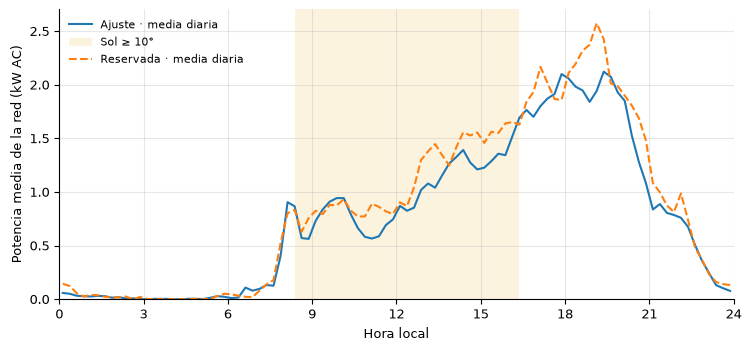

,pedida_kwh,kwh_dia,pico_red_kw,p95_red_kw,fuera_sol_pct,pendiente_kwh
periodo,,,,,,
ajuste,388.372,18.490,3.752,2.216,54.879,0.089
reservada,145.890,20.841,3.850,2.365,49.907,0.000


In [2]:
base, mb = "cargadores_100", d["modelo_base"]
fig, ax = plt.subplots(figsize=(7.4, 3.4), layout="constrained")
n = 24 * 60 // d["paso_min"]
reloj_h = (np.arange(n) + 0.5) * d["paso_min"] / 60
for periodo, estilo in (("ajuste", "-"), ("reservada", "--")):
    w, sol, reloj = curvas[periodo, mb, base]
    dias = len(reloj) // n
    media = w.sum(axis=0)[:dias * n].reshape(dias, n).mean(axis=0) / 1000
    ax.plot(reloj_h, media, estilo, label=f"{periodo.capitalize()} · media diaria")
    if periodo == "ajuste":
        frac_sol = sol[:, :dias * n].mean(axis=0).reshape(dias, n).mean(axis=0)
        ax.fill_between(reloj_h, 0, 1, where=frac_sol >= 0.5, transform=ax.get_xaxis_transform(), color="#f2c14e", alpha=0.18, lw=0, label=f"Sol ≥ {d['altura_solar_min_grados']}°")
ax.set(xlabel="Hora local", ylabel="Potencia media de la red (kW AC)", xticks=range(0, 25, 3), xlim=(0, 24), ylim=(0, None))
ax.legend(frameon=False)
guardar_figura(fig, "estacion_recarga", "T50_curva_red")
r = resumen.query("modelo == @mb and caso == @base").set_index("periodo")
display(r[["pedida_kwh", "kwh_dia", "pico_red_kw", "p95_red_kw", "fuera_sol_pct", "pendiente_kwh"]].round(3))

## Demanda por estación y elección de la estación a detallar

Siguiendo el plan, se toman con el ajuste y el Modelo A las estaciones con más energía total, más pico de potencia en 15 minutos y más energía fuera de las horas de sol. Una misma estación puede ganar en varios criterios. Se elige la que queda mejor clasificada sumando los puestos en los tres, con la energía total como desempate. La energía total fija los paneles, la que llega sin sol fija la batería y el pico, la potencia del inversor y de los cargadores: una estación que encabeza los tres es la cota de diseño para las demás. Después se comprueba la posición de cada candidata en la semana reservada y con el Modelo B. La mejor de las demás candidatas queda como alternativa para repetir el balance de T54.

station_id,891e8051d07ffff,891e8052a6bffff
criterios,pico;fuera_sol,energia
lon,12.48,12.49
lat,41.84,41.89
anclajes,8,11
llegadas,204,170
pedida_kwh,7.08,7.22
kwh_dia_media,0.34,0.34
kwh_dia_p95,0.63,0.74
pico_w,497.86,482.84
p95_w,91.43,91.43


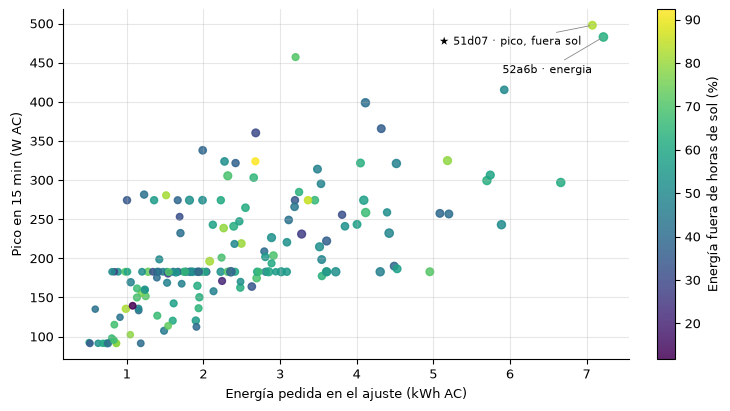

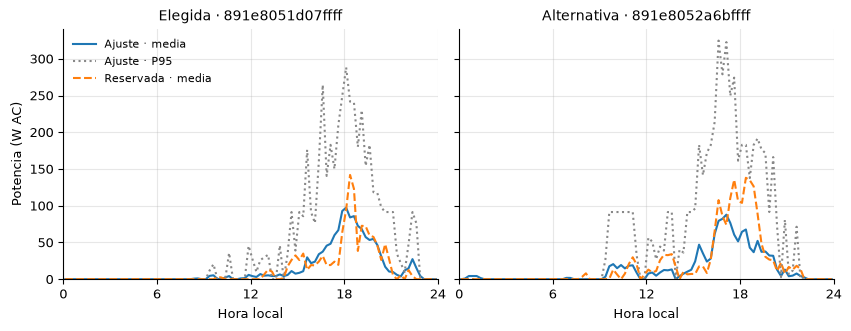

In [3]:
e = estaciones.query("caso == @base")
aj = e.query("periodo == 'ajuste' and modelo == @mb").set_index("station_id")
criterios = {"energia": "pedida_kwh", "pico": "pico_w", "fuera_sol": "fuera_sol_kwh"}
puestos = pd.DataFrame({c: aj[col].rank(ascending=False, method="min").astype(int) for c, col in criterios.items()})
gana = {}
for c, col in criterios.items():
    for station_id in aj[col].nlargest(d["candidatas_por_criterio"]).index:
        gana.setdefault(station_id, []).append(c)
columnas = ["lon", "lat", "anclajes", "llegadas", "pedida_kwh", "kwh_dia_media", "kwh_dia_p95", "pico_w", "p95_w", "fuera_sol_kwh", "fuera_sol_pct", "simultaneas_max"]
candidatas = aj.loc[list(gana), columnas].join(puestos.add_prefix("puesto_")).reset_index()
candidatas.insert(1, "criterios", [";".join(gana[s]) for s in candidatas["station_id"]])
candidatas["suma_puestos"] = candidatas[[f"puesto_{k}" for k in criterios]].sum(axis=1)
for periodo, modelo in (("reservada", mb), ("ajuste", "b"), ("reservada", "b")):
    g = e.query("periodo == @periodo and modelo == @modelo").set_index("station_id")["pedida_kwh"].rank(ascending=False, method="min")
    candidatas[f"puesto_energia_{periodo}_{modelo}"] = g.reindex(candidatas["station_id"]).astype(int).to_numpy()
candidatas = candidatas.sort_values(["suma_puestos", "pedida_kwh"], ascending=[True, False]).reset_index(drop=True)
candidatas["papel"] = ["elegida", "alternativa", *["candidata"] * (len(candidatas) - 2)][:len(candidatas)]
elegida = candidatas["station_id"].iloc[0]
alternativa = candidatas["station_id"].iloc[1] if len(candidatas) > 1 else None
guardar(candidatas, "T50_candidatas.csv")
display(candidatas.set_index("station_id").round(2).T)
corto = lambda s: s[-9:-4]

fig, ax = plt.subplots(figsize=(7.2, 4.0), layout="constrained")
sc = ax.scatter(aj["pedida_kwh"], aj["pico_w"], c=aj["fuera_sol_pct"], s=14 + 2 * aj["anclajes"], cmap="viridis", alpha=0.85)
fig.colorbar(sc, ax=ax, label="Energía fuera de horas de sol (%)")
for k, c in candidatas.iterrows():
    texto = ("★ " if c["papel"] == "elegida" else "") + corto(c["station_id"]) + " · " + c["criterios"].replace(";", ", ").replace("_", " ")
    ax.annotate(texto, (c["pedida_kwh"], c["pico_w"]), xytext=(-8, -14 - 12 * k), textcoords="offset points", fontsize=8, ha="right",
                arrowprops={"arrowstyle": "-", "color": "#888", "lw": 0.6})
ax.set(xlabel="Energía pedida en el ajuste (kWh AC)", ylabel="Pico en 15 min (W AC)")
guardar_figura(fig, "estacion_recarga", "T50_estaciones")

mostradas = [s for s in (elegida, alternativa) if s]
fig, ejes = plt.subplots(1, len(mostradas), figsize=(8.4, 3.2), sharey=True, layout="constrained", squeeze=False)
for eje, station_id in zip(ejes[0], mostradas):
    fila = est.index[est["station_id"].eq(station_id)][0]
    for periodo, estilo in (("ajuste", "-"), ("reservada", "--")):
        w, sol, reloj = curvas[periodo, mb, base]
        dias = len(reloj) // n
        eje.plot(reloj_h, w[fila, :dias * n].reshape(dias, n).mean(axis=0), estilo, label=f"{periodo.capitalize()} · media")
        if periodo == "ajuste":
            eje.plot(reloj_h, np.quantile(w[fila, :dias * n].reshape(dias, n), d["cuantil"], axis=0), ":", color="#888", label="Ajuste · P95")
    papel = candidatas.set_index("station_id").loc[station_id, "papel"]
    eje.set(xlabel="Hora local", xticks=range(0, 25, 6), xlim=(0, 24), title=f"{papel.capitalize()} · {station_id}")
ejes[0, 0].set(ylabel="Potencia (W AC)", ylim=(0, None))
ejes[0, 0].legend(frameon=False)
guardar_figura(fig, "estacion_recarga", "T50_candidatas")

## Cargadores y cola

Con un cargador por anclaje, ¿llega a esperar alguna sesión? Si se ahorran cargadores, ¿cuánta energía se aplaza, cuánto se espera y cuánto queda pendiente al cerrar el periodo? La energía pedida es la misma en todos los casos; la cola solo la mueve en el tiempo y aplana el pico.

In [4]:
cmp = resumen.query("modelo == @mb").set_index(["periodo", "caso"])
display(cmp[["pico_red_kw", "aplazada_kwh", "pendiente_kwh", "estaciones_con_cola", "horas_con_cola", "sesiones_en_espera", "espera_media_min", "espera_p95_min", "espera_max_min"]].round(3))
display(estaciones.query("station_id == @elegida and modelo == @mb")[["periodo", "caso", "cargadores", "pico_w", "simultaneas_max", "horas_con_cola", "espera_media_min", "espera_max_min", "pendiente_kwh"]].round(2))

pico_red_kw  aplazada_kwh  pendiente_kwh  \
periodo   caso                                                       
ajuste    ideal                 3.752         0.000          0.089   
          cargadores_100        3.752         0.000          0.089   
          cargadores_50         3.595         0.754          0.089   
          cargadores_25         3.512        14.285          0.089   
reservada ideal                 3.850         0.000          0.000   
          cargadores_100        3.850         0.000          0.000   
          cargadores_50         3.850         0.461          0.000   
          cargadores_25         3.767         5.037          0.000   

                          estaciones_con_cola  horas_con_cola  \
periodo   caso                                                  
ajuste    ideal                             0               0   
          cargadores_100                    0               0   
          cargadores_50                    15              28   
          cargadores_25                    99             388   
reservada ideal                             0               0   
          cargadores_100                    0               0   
          cargadores_50                    10              13   
          cargadores_25                    63             134   

                          sesiones_en_espera  espera_media_min  \
periodo   caso                                                   
ajuste    ideal                            0             0.000   
          cargadores_100                   0             0.000   
          cargadores_50                   28            16.807   
          cargadores_25                  402            19.997   
reservada ideal                            0             0.000   
          cargadores_100                   0             0.000   
          cargadores_50                   17            12.184   
          cargadores_25                  148            18.327   

                          espera_p95_min  espera_max_min  
periodo   caso                                            
ajuste    ideal                      0.0           0.000  
          cargadores_100             0.0           0.000  
          cargadores_50              0.0          73.076  
          cargadores_25              0.0         146.144  
reservada ideal                      0.0           0.000  
          cargadores_100             0.0           0.000  
          cargadores_50              0.0          48.333  
          cargadores_25              0.0         114.009

,periodo,caso,cargadores,pico_w,simultaneas_max,horas_con_cola,espera_media_min,espera_max_min,pendiente_kwh
95,ajuste,ideal,8,497.86,6,0,0.00,0.00,0.0
254,ajuste,cargadores_100,8,497.86,6,0,0.00,0.00,0.0
413,ajuste,cargadores_50,4,365.71,4,3,0.29,31.65,0.0
572,ajuste,cargadores_25,2,182.86,2,27,5.69,82.81,0.0
1367,reservada,ideal,8,535.14,7,0,0.00,0.00,0.0
1526,reservada,cargadores_100,8,535.14,7,0,0.00,0.00,0.0
1685,reservada,cargadores_50,4,353.12,4,1,0.78,19.22,0.0
1844,reservada,cargadores_25,2,182.86,2,5,6.88,58.98,0.0


## Datos de la web

Se exportan el resumen, las candidatas, el día medio de la red y de cada estación en el caso base (15 minutos, W AC) y la tabla por estación del ajuste y la reserva con el Modelo A.

In [5]:
perfil_red, perfil_est = {}, []
for periodo in ("ajuste", "reservada"):
    w, sol, reloj = curvas[periodo, mb, base]
    dias = len(reloj) // n
    perfil_red[periodo] = (w.sum(axis=0)[:dias * n].reshape(dias, n).mean(axis=0)).round(3).tolist()
    media = w[:, :dias * n].reshape(len(est), dias, n).mean(axis=1)
    perfil_est += [{"periodo": periodo, "station_id": s, "w": media[i].round(3).tolist()} for i, s in enumerate(est["station_id"])]
w, sol, reloj = curvas["ajuste", mb, base]
dias = len(reloj) // n
exportar("fase3", "t50_demanda", {
    "eta_cargador": eta, "potencia_bateria_w": cargar_config()["patinete"]["bateria_wh"] / cargar_config()["patinete"]["tiempo_recarga_h"],
    "altura_solar_min": d["altura_solar_min_grados"], "minutos": (np.arange(n) * d["paso_min"]).tolist(),
    "sol": (sol[:, :dias * n].mean(axis=0).reshape(dias, n).mean(axis=0) >= 0.5).tolist(),
    "resumen": resumen, "candidatas": candidatas, "elegida": elegida, "alternativa": alternativa, "perfil_red": perfil_red, "perfil_estaciones": perfil_est,
    "estaciones": e.query("modelo == @mb")[["periodo", "station_id", "lon", "lat", "anclajes", "llegadas", "pedida_kwh", "kwh_dia_media", "kwh_dia_p95", "pico_w", "p95_w", "simultaneas_max", "fuera_sol_pct"]],
})

In [6]:
ra, rr = (resumen.query("periodo == @p and modelo == @mb and caso == @base").iloc[0] for p in ("ajuste", "reservada"))
rb = resumen.query("periodo == 'ajuste' and modelo == 'b' and caso == @base").iloc[0]
c25 = resumen.query("periodo == 'ajuste' and modelo == @mb and caso == 'cargadores_25'").iloc[0]
c50 = resumen.query("periodo == 'ajuste' and modelo == @mb and caso == 'cargadores_50'").iloc[0]
el, alt = (candidatas.set_index("station_id").loc[x] for x in (elegida, alternativa))
etas = d["eta_cargador_sensibilidad"]
num = lambda x, k=1: f"{x:,.{k}f}".replace(",", " ").replace(".", ",")
display(Markdown(f"""## Conclusiones
- En el ajuste, la red habitual pide **{num(ra.pedida_kwh)} kWh** desde la red eléctrica para reponer {num(ra.llegadas, 0)} llegadas, **{num(ra.kwh_dia, 2)} kWh/día** ({num(rr.kwh_dia, 2)} en la reserva). Con rendimientos de cargador entre {num(etas[0], 2)} y {num(etas[1], 2)} la cifra se mueve entre {num(ra[f'pedida_kwh_eta_{etas[1]:.2f}'])} y {num(ra[f'pedida_kwh_eta_{etas[0]:.2f}'])} kWh. El Modelo B da {num(rb.pedida_kwh)} kWh.
- El pico de la red es **{num(ra.pico_red_kw, 2)} kW** (P95 de {num(ra.p95_red_kw, 2)} kW) y **{num(ra.fuera_sol_pct, 0)} %** de la energía se pide con el sol por debajo de {d['altura_solar_min_grados']}°. Sin batería, más de la mitad de la recarga no coincidiría con la producción solar.
- Con un cargador por anclaje ninguna sesión espera: como máximo cargan **{ra.simultaneas_max}** patinetes a la vez en una estación. Con la mitad de cargadores esperan {num(c50.sesiones_en_espera, 0)} sesiones; con la cuarta parte, {num(c25.sesiones_en_espera, 0)}, una media de {num(c25.espera_media_min, 0)} min y como mucho {num(c25.espera_max_min, 0)} min. Con cargador en todos los anclajes el pico es el del perfil ideal; dejar solo uno de cada cuatro lo baja de {num(ra.pico_red_kw, 2)} a {num(c25.pico_red_kw, 2)} kW a cambio de esas esperas.
- Se detalla la estación **{elegida}**: {num(el.pedida_kwh)} kWh en el ajuste ({num(el.kwh_dia_media, 2)} kWh/día de media y {num(el.kwh_dia_p95, 2)} de P95), pico de {num(el.pico_w, 0)} W y {num(el.fuera_sol_pct, 0)} % fuera de horas de sol. Ocupa los puestos {el.puesto_energia}, {el.puesto_pico} y {el.puesto_fuera_sol} en energía, pico y energía sin sol, y el {el.puesto_energia_reservada_a}.º en energía en la reserva. La alternativa, **{alternativa}**, pide {num(alt.pedida_kwh)} kWh con {num(alt.fuera_sol_pct, 0)} % sin sol y es la {alt.puesto_energia_reservada_a}.ª en la reserva: la diferencia entre ambas es pequeña y T54 repite el balance con las dos. T51 compara tres emplazamientos para la elegida y T54 usa la serie horaria `T50_perfil_hora.csv.gz`."""))

## Conclusiones
- En el ajuste, la red habitual pide **388,4 kWh** desde la red eléctrica para reponer 12 750 llegadas, **18,49 kWh/día** (20,84 en la reserva). Con rendimientos de cargador entre 0,85 y 0,95 la cifra se mueve entre 367,9 y 411,2 kWh. El Modelo B da 387,6 kWh.
- El pico de la red es **3,75 kW** (P95 de 2,22 kW) y **55 %** de la energía se pide con el sol por debajo de 10°. Sin batería, más de la mitad de la recarga no coincidiría con la producción solar.
- Con un cargador por anclaje ninguna sesión espera: como máximo cargan **6** patinetes a la vez en una estación. Con la mitad de cargadores esperan 28 sesiones; con la cuarta parte, 402, una media de 20 min y como mucho 146 min. Con cargador en todos los anclajes el pico es el del perfil ideal; dejar solo uno de cada cuatro lo baja de 3,75 a 3,51 kW a cambio de esas esperas.
- Se detalla la estación **891e8051d07ffff**: 7,1 kWh en el ajuste (0,34 kWh/día de media y 0,63 de P95), pico de 498 W y 83 % fuera de horas de sol. Ocupa los puestos 2, 1 y 1 en energía, pico y energía sin sol, y el 5.º en energía en la reserva. La alternativa, **891e8052a6bffff**, pide 7,2 kWh con 63 % sin sol y es la 1.ª en la reserva: la diferencia entre ambas es pequeña y T54 repite el balance con las dos. T51 compara tres emplazamientos para la elegida y T54 usa la serie horaria `T50_perfil_hora.csv.gz`.